# Train the last layer

## Imports 

In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src")))

In [2]:
import tensorflow as tf
import numpy as np
import os, glob
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from preprocessing import AudioPipeline
from preprocessing.dataset_pipeline import load_and_preprocess, make_dataset
from preprocessing.transfer_model import build_transfer_model
from sklearn.metrics import classification_report, confusion_matrix

I0000 00:00:1780391433.021992   28041 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1780391433.047134   28041 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1780391433.782916   28041 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Config

In [3]:
DATA_DIR    = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/data/raw"
CLASSES     = ["talky", "silence", "unknown"]
BATCH_SIZE  = 16      
EPOCHS   = 50       # backbone gelé
LR       = 1e-3
KERAS_PATH  = "/home/f24achba/Documents/Edge AI/52-Hertz-KWS/src/models/miniresnetv2_s1_64x50_tl.keras"

pipeline = AudioPipeline("/home/f24achba/Documents/Edge AI/52-Hertz-KWS/configuration/config.yaml")

## Chargement des chemins + labels 

In [4]:
all_paths, all_labels = [], []

for label_idx, class_name in enumerate(CLASSES):
    wavs = glob.glob(os.path.join(DATA_DIR, class_name, "*.wav"))
    all_paths  += wavs
    all_labels += [label_idx] * len(wavs)
    print(f"  {class_name:10s} → {len(wavs)} fichiers")

all_paths  = np.array(all_paths)
all_labels = np.array(all_labels)
print(f"\nTotal : {len(all_paths)} samples\n")

  talky      → 295 fichiers
  silence    → 135 fichiers
  unknown    → 326 fichiers

Total : 756 samples



## Split 

In [5]:
# train 70% / val 15% / test 15%
X_train, X_temp, y_train, y_temp = train_test_split(
    all_paths, all_labels,
    test_size=0.30,
    stratify=all_labels,    
    random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"Train : {len(X_train)} | Val : {len(X_val)} | Test : {len(X_test)}")


Train : 529 | Val : 113 | Test : 114


## Class weights 

In [6]:
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(f"\nClass weights : {class_weight_dict}")


Class weights : {0: 0.8559870550161812, 1: 1.856140350877193, 2: 0.7733918128654971}


## tf.data pipeline 

In [7]:
train_ds = make_dataset(X_train, y_train, BATCH_SIZE, augment=True)
val_ds   = make_dataset(X_val,   y_val, BATCH_SIZE,  augment=False)
test_ds  = make_dataset(X_test,  y_test, BATCH_SIZE, augment=False)

W0000 00:00:1780391434.479761   28100 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1780391434.522640   28041 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


## model 

In [8]:

model = build_transfer_model(KERAS_PATH, num_classes=3)
model.compile(
    optimizer=tf.keras.optimizers.Adam(LR),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "miniresnet_kws"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_4             │ (None, 64, 50, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 70, 56, 1) │          0 │ input_4[0][0]     │
│ (ZeroPadding2D)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 32, 25,    │      3,200 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 34, 27,    │          0 │ conv1_conv[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 16, 13,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │        256 │ pool1_pool[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_preac… │ (None, 16, 13,    │          0 │ conv2_block1_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 16, 13,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 16, 13,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_pad  │ (None, 18, 15,    │          0 │ conv2_block1_1_r… │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 16, 13,    │      4,160 │ conv2_block1_pre… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 16, 13,    │     36,864 │ conv2_block1_2_p… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_out    │ (None, 16, 13,    │          0 │ conv2_block1_0_c… │
│ (Add)               │ 64)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │        256 │ conv2_block1_out… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_preac… │ (None, 16, 13,    │          0 │ conv2_block2_pre… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 16, 13,    │      4,096 │ conv2_block2_pre

 Total params: 101,315 (395.76 KB)

 Trainable params: 10,755 (42.01 KB)

 Non-trainable params: 90,560 (353.75 KB)

## Callbacks 

In [9]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_model_resnet_v1s2_test.keras",
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,                  # généreux : courbes bruitées avec peu de data
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.TensorBoard(log_dir="./logs")
]


## Training

In [10]:
print("\n Feature extraction (backbone gelé)")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict   # compense le déséquilibre
)


 Feature extraction (backbone gelé)
Epoch 1/50
17/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3241 - loss: 1.0753 
Epoch 1: val_accuracy improved from None to 0.17699, saving model to best_model_resnet_v1s2_test.keras
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.4026 - loss: 1.1032 - val_accuracy: 0.1770 - val_loss: 1.1086 - learning_rate: 0.0010
Epoch 2/50
33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3017 - loss: 1.0831
Epoch 2: val_accuracy improved from 0.17699 to 0.53097, saving model to best_model_resnet_v1s2_test.keras
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.3819 - loss: 1.0795 - val_accuracy: 0.5310 - val_loss: 1.0568 - learning_rate: 0.0010
Epoch 3/50
33/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4887 - loss: 1.0622
Epoch 3: val_accuracy improved from 0.53097 to 0.72566, saving model to best_model_resnet_v1s2_test.keras
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.5198 - loss: 1.0600 - val_accuracy: 0.7257 - val_loss: 1.0461

## Best model 

In [11]:
model = tf.keras.models.load_model("best_model_resnet_v1s2_test.keras")  
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"Test accuracy : {acc:.3f}")

Test accuracy : 0.886


## Confusion matrix

In [12]:

y_pred = np.argmax(model.predict(test_ds), axis=1)
y_true = np.concatenate([y for _, y in test_ds], axis=0)
print(classification_report(y_true, y_pred, target_names=["talky","silence","unknown"]))

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
              precision    recall  f1-score   support

       talky       0.91      0.91      0.91        45
     silence       0.93      0.70      0.80        20
     unknown       0.85      0.94      0.89        49

    accuracy                           0.89       114
   macro avg       0.90      0.85      0.87       114
weighted avg       0.89      0.89      0.88       114



## Tester les moments de convergence

In [13]:
best_epoch = np.argmax(history.history["val_accuracy"]) + 1
best_val_acc = np.max(history.history["val_accuracy"])

print(f"Best Epoch : {best_epoch}")
print(f"Val Acc : {best_val_acc})")

Best Epoch : 15
Val Acc : 0.9380530714988708)


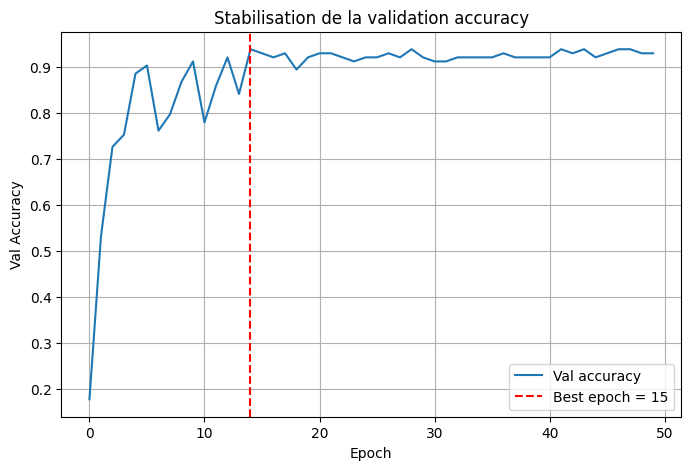

Best val acc: 0.9380530714988708


In [14]:
import numpy as np
import matplotlib.pyplot as plt

val_acc = history.history["val_accuracy"]
best_epoch = np.argmax(val_acc)

plt.figure(figsize=(8,5))

plt.plot(val_acc, label="Val accuracy")
plt.axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch = {best_epoch+1}")

plt.xlabel("Epoch")
plt.ylabel("Val Accuracy")
plt.title("Stabilisation de la validation accuracy")
plt.legend()
plt.grid(True)

plt.show()

print("Best val acc:", val_acc[best_epoch])


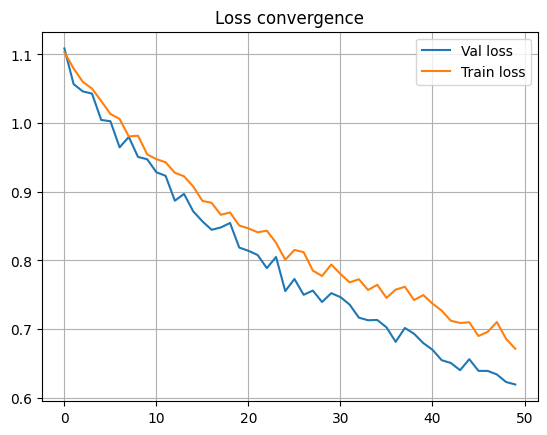

In [15]:
plt.plot(history.history["val_loss"], label="Val loss")
plt.plot(history.history["loss"], label="Train loss")
plt.legend()
plt.grid()
plt.title("Loss convergence")
plt.show()